In [203]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [204]:
df = pd.read_csv("/content/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [205]:
df.shape

(284807, 31)

In [206]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [207]:
df['Class'].value_counts()
# fraudulent (Class = 1)
# legitimate (Class = 0)

,count
Class,
0,284315
1,492


In [208]:
df.duplicated().sum()

np.int64(1081)

In [209]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [210]:
display(df[df.duplicated(keep=False)].head(10))

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [211]:
rows_before = len(df)
df  = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

In [212]:
(df["Class"].value_counts(normalize=True) * 100).round(4)

,proportion
Class,
0,99.8333
1,0.1667


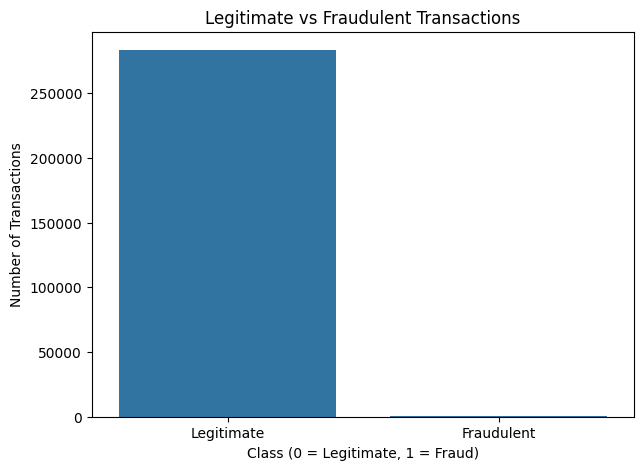

In [213]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Class')
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

In [214]:
display(df["Amount"].describe())

,Amount
count,283726.000000
mean,88.472687
std,250.399437
min,0.000000
25%,5.600000
50%,22.000000
75%,77.510000
max,25691.160000


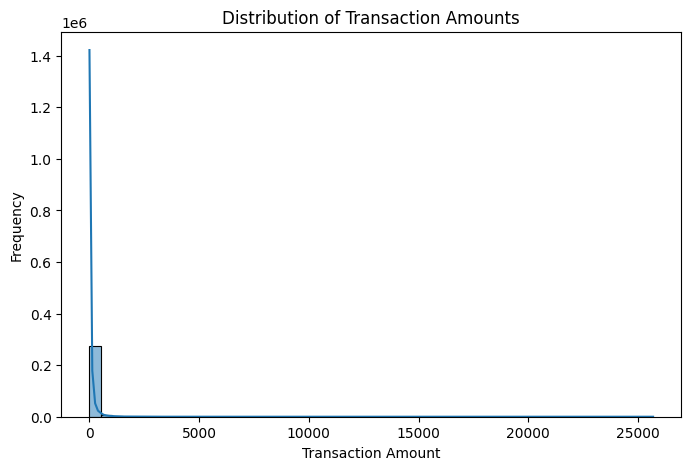

In [215]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Amount", bins=50, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

In [216]:
amount_comparison = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max"]
)
display(amount_comparison.round(2))

,count,mean,median,min,max
Class,,,,,
0,283253,88.41,22.00,0.0,25691.16
1,473,123.87,9.82,0.0,2125.87


In [217]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [218]:
X.shape
y.shape
X.columns.tolist()
y.value_counts()

,count
Class,
0,283253
1,473


In [219]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.shape
X_test.shape
y_train.shape
y_test.shape
y_train.value_counts()
y_test.value_counts()

,count
Class,
0,56651
1,95


In [220]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nFraud cases in each set:")
print("Training:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())


Training set: (181584, 30)
Validation set: (45396, 30)
Test set: (56746, 30)

Fraud cases in each set:
Training: {0: 181282, 1: 302}
Validation: {0: 45320, 1: 76}
Test: {0: 56651, 1: 95}


In [221]:
scaler = StandardScaler()
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()
X_train["Amount"] = scaler.fit_transform(
    X_train[["Amount"]]
).ravel()
X_val["Amount"] = scaler.transform(
    X_val[["Amount"]]
).ravel()

X_test["Amount"] = scaler.transform(
    X_test[["Amount"]]
).ravel()

print("Training Amount mean:", round(X_train["Amount"].mean(), 4))
print("Validation Amount mean:", round(X_val["Amount"].mean(), 4))
print("Test Amount mean:", round(X_test["Amount"].mean(), 4))


Training Amount mean: -0.0
Validation Amount mean: -0.0008
Test Amount mean: 0.0016


In [222]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [223]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
y_test.iloc[:10].to_list()
y_pred[:10]
y_prob[:10].round(4)

array([0.0003, 0.0004, 0.0001, 0.0001, 0.0026, 0.0001, 0.0001, 0.0003,
       0.    , 0.0001])

In [224]:
classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud'], zero_division=0)

'              precision    recall  f1-score   support\n\n  Legitimate       1.00      1.00      1.00     56651\n       Fraud       0.85      0.59      0.70        95\n\n    accuracy                           1.00     56746\n   macro avg       0.92      0.79      0.85     56746\nweighted avg       1.00      1.00      1.00     56746\n'

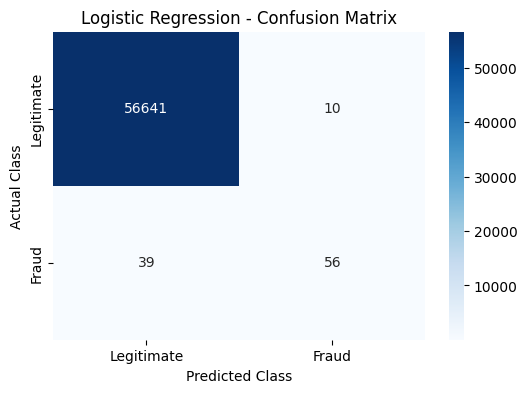

array([[56641,    10],
       [   39,    56]])

In [225]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()
cm

In [226]:
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
round(roc_auc, 4)
round(pr_auc, 4)

np.float64(0.6858)

In [227]:
%pip install -q imbalanced-learn

In [228]:
y_train.value_counts()

,count
Class,
0,181282
1,302


In [229]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
y_train_smote.value_counts()
X_train.shape
X_train_smote.shape

(362564, 30)

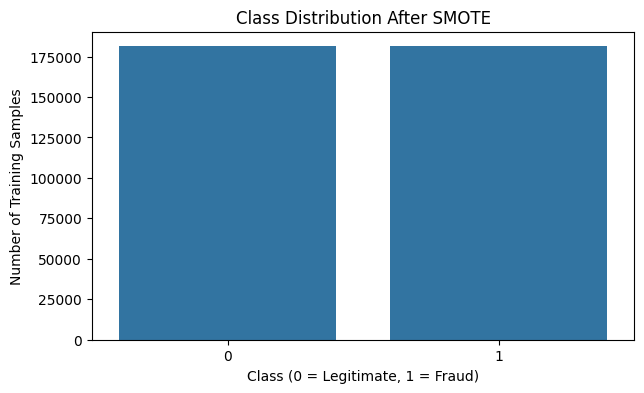

In [230]:
plt.figure(figsize=(7,4))
sns.countplot(x=y_train_smote)
plt.title('Class Distribution After SMOTE')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Training Samples')
plt.show()

In [231]:
smote_model = LogisticRegression(max_iter=1000, random_state=42)
smote_model.fit(X_train_smote, y_train_smote)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [232]:
y_pred_smote = smote_model.predict(X_test)
y_prob_smote = smote_model.predict_proba(X_test)[:, 1]

In [233]:
classification_report(y_test, y_pred_smote, target_names=['Legitimate', 'Fraud'], zero_division=0)
round(roc_auc_score(y_test, y_prob_smote), 4)
round(average_precision_score(y_test, y_prob_smote), 4)

np.float64(0.6913)

In [234]:
comparison = pd.DataFrame({
    "Model": ["Baseline Logistic Regression", "SMOTE Logistic Regression"],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_smote, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_smote, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_smote, zero_division=0)
    ],
    "PR-AUC": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, y_prob_smote)
    ]
})
display(comparison.round(4))

,Model,Precision,Recall,F1-score,PR-AUC
0,Baseline Logistic Regression,0.8485,0.5895,0.6957,0.6858
1,SMOTE Logistic Regression,0.1037,0.8632,0.1851,0.6913


In [235]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight="balanced_subsample")
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1,
                       random_state=42)

In [236]:
y_prob_val_rf = rf_model.predict_proba(X_val)[:, 1]
threshold_results = []

for threshold in [0.01, 0.05, 0.10, 0.20, 0.30, 0.50]:
    predictions = (y_prob_val_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False Positives": fp,
        "Missed Fraud": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,Missed Fraud
0,0.01,0.0731,0.8947,0.1352,862,8
1,0.05,0.6569,0.8816,0.7528,35,9
2,0.10,0.8571,0.8684,0.8627,11,10
3,0.20,0.9420,0.8553,0.8966,4,11
4,0.30,0.9420,0.8553,0.8966,4,11
5,0.50,0.9836,0.7895,0.8759,1,16


In [237]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [238]:
classification_report(y_test, y_pred_rf, target_names=['Legitimate', 'Fraud'], zero_division=0)
round(roc_auc_score(y_test, y_prob_rf), 4)
round(average_precision_score(y_test, y_prob_rf), 4)
confusion_matrix(y_test, y_pred_rf)

array([[56649,     2],
       [   28,    67]])

In [239]:
comparison = pd.DataFrame({
    "Model": ["Baseline Logistic Regression", "SMOTE Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_smote, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_smote, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_smote, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "PR-AUC": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, y_prob_smote),
        average_precision_score(y_test, y_prob_rf)
    ]
})
display(comparison.round(4))

,Model,Precision,Recall,F1-score,PR-AUC
0,Baseline Logistic Regression,0.8485,0.5895,0.6957,0.6858
1,SMOTE Logistic Regression,0.1037,0.8632,0.1851,0.6913
2,Random Forest,0.9710,0.7053,0.8171,0.8084


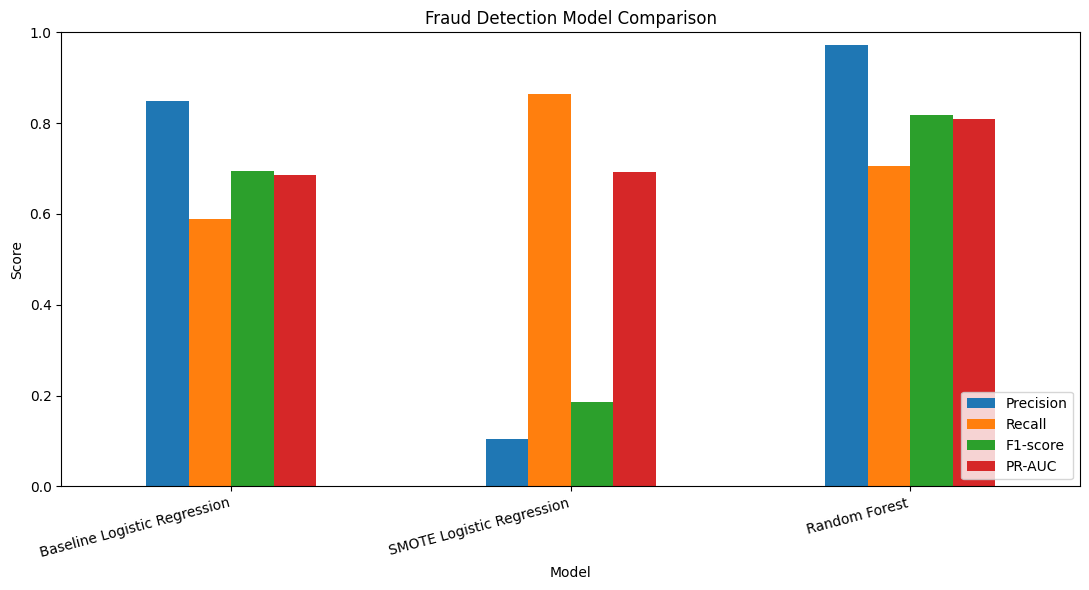

In [240]:
comparison.set_index("Model")[["Precision", "Recall", "F1-score", "PR-AUC"]].plot(kind="bar", figsize=(11,6))
plt.title("Fraud Detection Model Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=15,ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [241]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
display(feature_importance.head(15))

,Feature,Importance
14,V14,0.197356
10,V10,0.113699
12,V12,0.102899
4,V4,0.098202
17,V17,0.088732
3,V3,0.066100
16,V16,0.048781
11,V11,0.047376
2,V2,0.038059
9,V9,0.024093


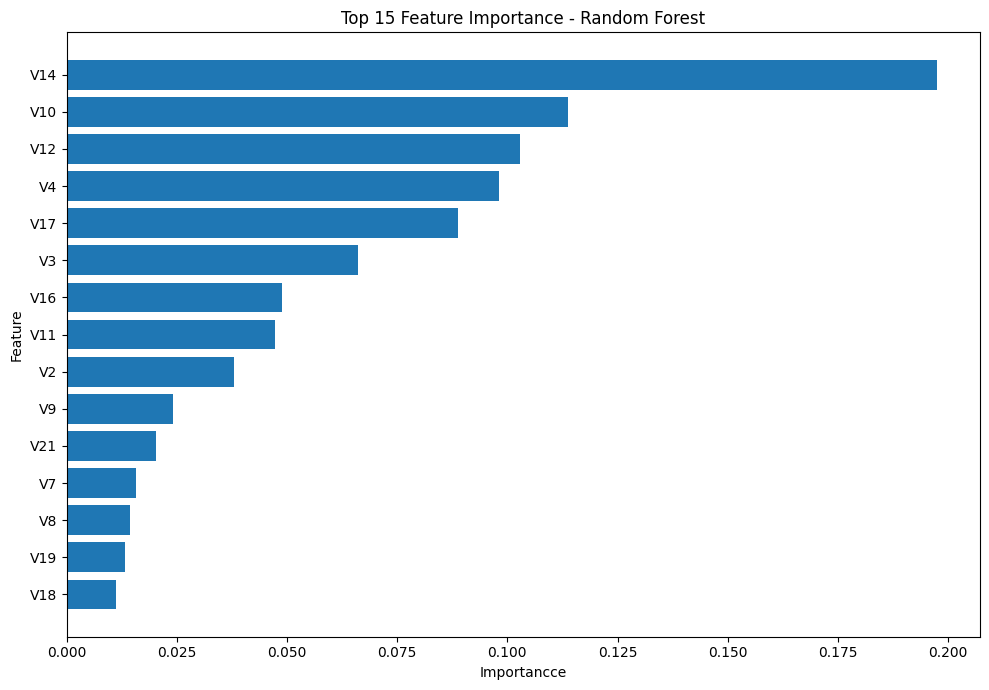

In [242]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)
plt.figure(figsize=(10,7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importancce")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

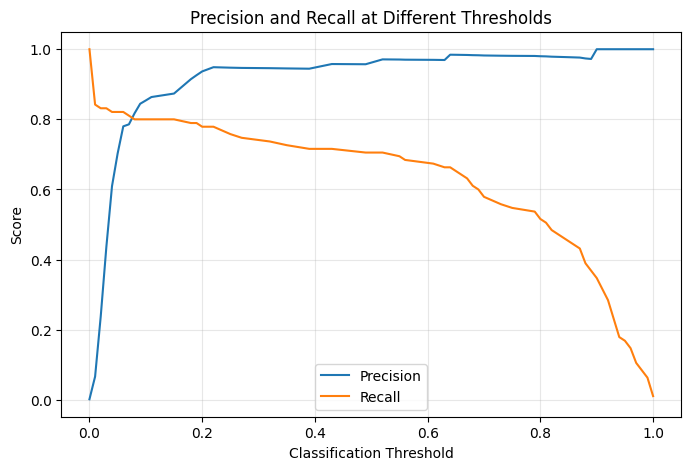

In [243]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_rf
)
plt.figure(figsize=(8,5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.legend()

plt.grid(alpha=0.3)
plt.show()

In [244]:
threshold_results = []
for threshold in [0., 0.3, 0.2]:
  predictions = (y_prob_rf >= threshold).astype(int)
  tn, fp, fn, tp = confusion_matrix(
      y_test, predictions, labels=[0,1]
  ).ravel()

  threshold_results.append({
      "Threshold": threshold,
      "Precision": precision_score(
          y_test, predictions, zero_division=0
      ),
      "Recall": recall_score(
          y_test, predictions, zero_division=0
      ),
      "F1-score": f1_score(
          y_test, predictions, zero_division=0
      ),
      "False Positives": fp,
      "Missed Fraud": fn
  })
display(pd.DataFrame(threshold_results).round(4))

,Threshold,Precision,Recall,F1-score,False Positives,Missed Fraud
0,0.0,0.0017,1.0000,0.0033,56651,0
1,0.3,0.9459,0.7368,0.8284,4,25
2,0.2,0.9367,0.7789,0.8506,5,21


In [245]:
best_row = threshold_df.loc[threshold_df["F1-score"].idxmax()]

best_threshold = best_row["Threshold"]

print("Selected Threshold:", best_threshold)
print("Validation Precision:", round(best_row["Precision"], 4))
print("Validation Recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-score"], 4))
print("False Positives:", int(best_row["False Positives"]))
print("Missed Fraud:", int(best_row["Missed Fraud"]))


Selected Threshold: 0.2
Validation Precision: 0.942
Validation Recall: 0.8553
Validation F1-score: 0.8966
False Positives: 4
Missed Fraud: 11


In [246]:
y_prob_test_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_final = (
    y_prob_test_rf >= best_threshold
).astype(int)

cm_final = confusion_matrix(
    y_test, y_pred_final, labels=[0, 1]
)

tn, fp, fn, tp = cm_final.ravel()

print("Selected Threshold:", best_threshold)
print("\nFinal Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(cm_final)

print("\nFraud Detection Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("Missed Fraud:", fn)
print("Fraud Detected:", tp)

print("\nROC-AUC:", round(
    roc_auc_score(y_test, y_prob_test_rf), 4
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob_test_rf), 4
))


Selected Threshold: 0.2

Final Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.94      0.78      0.85        95

    accuracy                           1.00     56746
   macro avg       0.97      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56646     5]
 [   21    74]]

Fraud Detection Results:
True Negatives: 56646
False Positives: 5
Missed Fraud: 21
Fraud Detected: 74

ROC-AUC: 0.9193
PR-AUC: 0.8084


In [247]:
def calculate_risk_score(transaction_data):
  fraud_probability = rf_model.predict_proba(
      transaction_data
  )[:,1]
  risk_score = fraud_probability * 100
  return risk_score

In [248]:
def assign_risk_category(score):
  if score < 20:
    return "Low Risk"
  elif score < 60:
    return "Medium Risk"
  else:
    return "High Risk"

In [249]:
sample_transactions = X_test.iloc[:5].copy()
sample_scores = calculate_risk_score(sample_transactions)
risk_results = pd.DataFrame({
    "Fraud_Probability_%": (sample_scores).round(2),
    "Risk_Score": (sample_scores).round(2),
    "Risk_Category": [
        assign_risk_category(score)
        for score in sample_scores
    ],
    "Actual_Class": y_test.loc[sample_transactions.index].values
})

display(risk_results)


,Fraud_Probability_%,Risk_Score,Risk_Category,Actual_Class
0,0.0,0.0,Low Risk,0
1,0.0,0.0,Low Risk,0
2,0.0,0.0,Low Risk,0
3,0.0,0.0,Low Risk,0
4,0.0,0.0,Low Risk,0


In [250]:
sample_transactions = X_test.iloc[:10].copy()
probabilities = rf_model.predict_proba(sample_transactions)[:,1]
probabilities
probabilities * 100
probabilities.max()

np.float64(0.0)

In [251]:
y_test.value_counts()
pd.Series(rf_model.predict(X_test)).value_counts()
rf_model.predict_proba(X_test)[:,1].max()

np.float64(1.0)

In [252]:
sample_transactions = X_test.iloc[:10].copy()
probabilities = rf_model.predict_proba(sample_transactions)[:,1]
for i, probability in enumerate(probabilities):
  print(
      f"Transaction {i+1}: "
      f"Probability = {probability:.8f} "
      f"Risk Score = {probability * 100:.6f}"
  )

Transaction 1: Probability = 0.00000000 Risk Score = 0.000000
Transaction 2: Probability = 0.00000000 Risk Score = 0.000000
Transaction 3: Probability = 0.00000000 Risk Score = 0.000000
Transaction 4: Probability = 0.00000000 Risk Score = 0.000000
Transaction 5: Probability = 0.00000000 Risk Score = 0.000000
Transaction 6: Probability = 0.00000000 Risk Score = 0.000000
Transaction 7: Probability = 0.00000000 Risk Score = 0.000000
Transaction 8: Probability = 0.00000000 Risk Score = 0.000000
Transaction 9: Probability = 0.00000000 Risk Score = 0.000000
Transaction 10: Probability = 0.00000000 Risk Score = 0.000000


In [253]:
all_probabilities = rf_model.predict_proba(X_test)[:,1]
risk_table = pd.DataFrame({
    "Fraud_Probability": all_probabilities,
    "Risk_Score": all_probabilities * 100,
    "Actual_Class": y_test.to_numpy()
}, index=X_test.index)
display(
    risk_table.sort_values(
        by="Fraud_Probability",
        ascending=False
    ).head(10).round(6)
)

,Fraud_Probability,Risk_Score,Actual_Class
42588,1.00,100.0,1
42755,0.99,99.0,1
150337,0.99,99.0,1
41828,0.99,99.0,1
15683,0.99,99.0,1
15423,0.99,99.0,1
43498,0.98,98.0,1
150420,0.98,98.0,1
154122,0.97,97.0,1
222791,0.97,97.0,1


In [254]:
all_probabilities = rf_model.predict_proba(X_test)[:, 1]
all_probabilities.min()
all_probabilities.max()
(all_probabilities > 0).sum()
(all_probabilities == 0).sum()
len(np.unique(all_probabilities))
pd.Series(rf_model.predict(X_test)).value_counts()
[f"{p:.10f}" for p in all_probabilities[:10]]


['0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000',
 '0.0000000000']

In [255]:
all_probabilities = rf_model.predict_proba(X_test)[:, 1]
risk_table = pd.DataFrame({
    "Fraud_Probability_%": all_probabilities * 100,
    "Risk_Score": all_probabilities * 100,
    "Predicted_Class": (all_probabilities >= 0.5).astype(int),
    "Actual_Class": y_test.to_numpy()
}, index=X_test.index)
top_10_risks = risk_table.sort_values(
    by="Fraud_Probability_%",
    ascending=False
).head(10)

display(top_10_risks.round(2))


,Fraud_Probability_%,Risk_Score,Predicted_Class,Actual_Class
42588,100.0,100.0,1,1
42755,99.0,99.0,1,1
150337,99.0,99.0,1,1
41828,99.0,99.0,1,1
15683,99.0,99.0,1,1
15423,99.0,99.0,1,1
43498,98.0,98.0,1,1
150420,98.0,98.0,1,1
154122,97.0,97.0,1,1
222791,97.0,97.0,1,1


In [256]:
def predict_transaction_risk(transaction_data):

    transaction_data = transaction_data[X_train.columns].copy()

    transaction_data["Amount"] = scaler.transform(
        transaction_data[["Amount"]]
    ).ravel()

    fraud_probability = rf_model.predict_proba(
        transaction_data
    )[0, 1]

    risk_score = fraud_probability * 100

    predicted_class = int(
        fraud_probability >= best_threshold
    )

    if risk_score < 20:
        risk_category = "Low Risk"
    elif risk_score < 60:
        risk_category = "Medium Risk"
    else:
        risk_category = "High Risk"

    return {
        "Fraud Probability (%)": round(risk_score, 2),
        "Risk Score": round(risk_score, 2),
        "Risk Category": risk_category,
        "Selected Threshold (%)": round(
            best_threshold * 100, 2
        ),
        "Predicted Class": predicted_class,
        "Prediction": (
            "Fraudulent" if predicted_class == 1
            else "Legitimate"
        )
    }


In [257]:
sample_transaction = X_test.iloc[[0]].copy()

sample_transaction["Amount"] = (
    sample_transaction["Amount"] * scaler.scale_[0]
    + scaler.mean_[0]
)

result = predict_transaction_risk(sample_transaction)

for key, value in result.items():
    print(f"{key}: {value}")

Fraud Probability (%): 0.0
Risk Score: 0.0
Risk Category: Low Risk
Selected Threshold (%): 20.0
Predicted Class: 0
Prediction: Legitimate
